<a href="https://colab.research.google.com/github/rare-mubin/ProjectEdge/blob/main/Edge_Vision_RL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Edge Vision RL — Joint Model Selection & Partitioning

Trains an A2C policy to choose, **per video frame**, which DNN complexity to
run (light / medium / heavy) and where to split computation between a client
device and an edge server — trading off accuracy, latency, and energy.

**How to use:** Runtime → Run all. Configure the dataset and hyperparameters
in the form cells below; everything else runs top to bottom.

> **What this measures.** Delay, energy, and accuracy come from a
> **lookup-table cost model**, not from executing a real network on frames.
> See [Known limitation](#scrollTo=known_limitation) at the bottom — this
> matters for how results should be described.

## 1. Environment

In [ ]:
!pip install -q opencv-python-headless torch numpy matplotlib
!pip install --upgrade kaggle

import torch
print(f"PyTorch {torch.__version__}")
print(f"GPU available: {torch.cuda.is_available()}"
      + (f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else ""))
print()
print("Note: the A2C network here is tiny (7->64->64 MLP), so a GPU gives")
print("little benefit -- the real bottleneck is decoding and analyzing frames")
print("on the CPU. A CPU runtime is fine for this notebook.")

PyTorch 2.11.0+cu128
GPU available: True (Tesla T4)

Note: the A2C network here is tiny (7->64->64 MLP), so a GPU gives
little benefit -- the real bottleneck is decoding and analyzing frames
on the CPU. A CPU runtime is fine for this notebook.


## 2. Dataset

Three options. **Synthetic** needs no setup and is good for a first run;
the other two use the real TuSimple lane-detection frames.

| Source | Setup needed |
|---|---|
| `synthetic` | None — generates placeholder frames |
| `kaggle` | A `kaggle.json` API token ([how to get one](https://www.kaggle.com/docs/api)) |
| `drive` | TuSimple already saved in your Google Drive |

Colab runtimes are ephemeral, so a Kaggle download has to be repeated each
time the runtime restarts. Drive persists across sessions.

In [ ]:
#@title Choose dataset source { display-mode: "form" }
DATASET_SOURCE = "kaggle"  #@param ["synthetic", "kaggle", "drive"]
DRIVE_PATH = "/content/drive/MyDrive/TuSimple/train_set/clips"  #@param {type:"string"}

import os

if DATASET_SOURCE == "kaggle":
    from google.colab import files
    print("Upload your kaggle.json when prompted...")
    files.upload()
    os.makedirs('/root/.kaggle', exist_ok=True)
    !mv -f kaggle.json /root/.kaggle/ 2>/dev/null
    !chmod 600 /root/.kaggle/kaggle.json
    !pip install -q kaggle
    !kaggle datasets download -d manideep1108/tusimple -p /content/tusimple --unzip
    DATASET_DIR = "/content/tusimple/TUSimple/train_set/clips"

elif DATASET_SOURCE == "drive":
    from google.colab import drive
    drive.mount('/content/drive')
    DATASET_DIR = DRIVE_PATH

else:
    # No real frames -- the loader below falls back to synthetic generation.
    DATASET_DIR = "/content/__synthetic__"

print(f"\nDATASET_DIR = {DATASET_DIR}")
print(f"Exists: {os.path.exists(DATASET_DIR)}"
      + ("  (expected for synthetic mode)" if DATASET_SOURCE == "synthetic" else ""))

Upload your kaggle.json when prompted...


chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/manideep1108/tusimple
License(s): copyright-authors
  1% 133M/21.6G [00:08<24:14, 15.9MB/s]
User cancelled operation

DATASET_DIR = /content/tusimple/TUSimple/train_set/clips
Exists: True


## 3. Configuration

`w_acc / w_delay / w_energy` weight the three reward terms, which are each
normalized to roughly 0–1 before weighting. The defaults (0.7 / 0.15 / 0.15)
were chosen because lower accuracy weights let the policy collapse to always
picking the cheapest action regardless of scene content — see the reward cell
in §7 for the detail.

`frame_sampling` matters once the dataset is much larger than
`episodes × steps_per_episode`: `sequential` only ever visits the first
`episodes × steps_per_episode` frames in sorted order, while `random` draws
across the whole dataset.

In [ ]:
#@title Hyperparameters { display-mode: "form" }
EPISODES = 200  #@param {type:"integer"}
STEPS_PER_EPISODE = 30  #@param {type:"integer"}
FRAME_SAMPLING = "random"  #@param ["random", "sequential", "full-pass"]
SEED = 42  #@param {type:"integer"}
NUM_SEEDS = 1  #@param {type:"slider", min:1, max:5, step:1}

W_ACC = 0.7  #@param {type:"number"}
W_DELAY = 0.15  #@param {type:"number"}
W_ENERGY = 0.15  #@param {type:"number"}

LEARNING_RATE = 0.003  #@param {type:"number"}
GAMMA = 0.95  #@param {type:"number"}
UPDATE_EVERY = 5  #@param {type:"integer"}

_w_sum = W_ACC + W_DELAY + W_ENERGY
if abs(_w_sum - 1.0) > 1e-6:
    print(f"[Warning] reward weights sum to {_w_sum:.3f}, not 1.0 -- "
          f"rewards will still work but are harder to compare across runs.")
print(f"{EPISODES} episodes x {STEPS_PER_EPISODE} steps, sampling={FRAME_SAMPLING}, seed={SEED}")

200 episodes x 30 steps, sampling=random, seed=42


## 4. Imports and helpers

In [ ]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from datetime import datetime

try:
    import cv2
    CV2_AVAILABLE = True
except ImportError:
    print("OpenCV unavailable -- synthetic frames only.")
    cv2 = None
    CV2_AVAILABLE = False


def set_seed(seed):
    """Seed every source of randomness, so multi-seed runs are independent."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def safe_mean(values):
    """Mean over completed (non-dropped) frames; 0.0 instead of NaN when empty."""
    valid = [v for v in values if v > 0.0]
    return float(np.mean(valid)) if valid else 0.0

## 5. Frame loading

The scan is **recursive** because TuSimple nests frames two levels down
(`clips/<batch>/<clip_id>/1.jpg`). A flat `os.listdir` would find nothing and
silently fall through to synthetic frames.

In [ ]:
def get_dataset_frame_paths(directory):
    if not CV2_AVAILABLE or not os.path.exists(directory):
        print(f"[Info] No real frames at '{directory}' -- using synthetic generator.")
        return []

    exts = ('.png', '.jpg', '.jpeg', '.bmp')
    paths = [os.path.join(root, f)
             for root, _dirs, files in os.walk(directory)
             for f in files if f.lower().endswith(exts)]
    paths.sort()

    if not paths:
        print(f"[Info] No images found under '{directory}' -- using synthetic generator.")
    return paths


def load_real_frame(frame_path):
    img = cv2.imread(frame_path)
    if img is None:
        raise ValueError(f"Failed to decode: {frame_path}")
    return cv2.resize(img, (640, 640))


def generate_synthetic_frame(complexity_type='low'):
    """Stand-in frames at three visual complexity levels, for when no real
    dataset is available."""
    img = np.zeros((640, 640, 3), dtype=np.uint8)
    if not cv2:
        return np.random.randint(0, 256, (640, 640, 3), dtype=np.uint8)

    if complexity_type == 'low':
        cv2.circle(img, (320, 320), 120, (255, 255, 255), -1)
    elif complexity_type == 'medium':
        cv2.rectangle(img, (150, 150), (490, 490), (255, 255, 255), 5)
        cv2.putText(img, "Edge Vision", (200, 320), cv2.FONT_HERSHEY_SIMPLEX,
                    1.2, (255, 255, 255), 3)
    else:
        for _ in range(80):
            pt1 = (random.randint(0, 639), random.randint(0, 639))
            pt2 = (random.randint(0, 639), random.randint(0, 639))
            color = tuple(random.randint(100, 255) for _ in range(3))
            cv2.line(img, pt1, pt2, color, random.randint(1, 3))
    return img


FRAME_PATHS = get_dataset_frame_paths(DATASET_DIR)
USE_REAL_DATASET = len(FRAME_PATHS) > 0
if USE_REAL_DATASET:
    print(f"Loaded {len(FRAME_PATHS):,} real frames.")

Loaded 72,520 real frames.


## 6. Image complexity analyzer

Two cheap per-frame signals feed the policy's state: **Shannon entropy** of
the grayscale histogram (how much information is in the image) and **Canny
edge density** (how much structure). Both take milliseconds — far less than
the inference they're used to schedule.

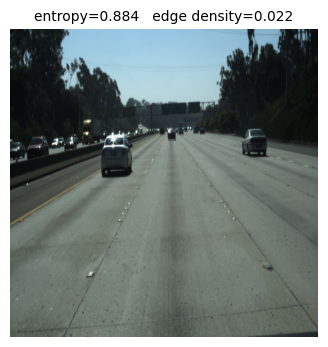

In [ ]:
class ImageAnalyzer:
    @staticmethod
    def compute_entropy(gray_img):
        hist = (cv2.calcHist([gray_img], [0], None, [256], [0, 256]) if cv2
                else np.histogram(gray_img, bins=256, range=(0, 256))[0])
        hist = hist.ravel() / (hist.sum() + 1e-10)
        prob = hist[hist > 0]
        return -np.sum(prob * np.log2(prob))

    @staticmethod
    def compute_edge_density(gray_img):
        if cv2:
            edges = cv2.Canny(gray_img, 100, 200)
            return np.sum(edges > 0) / edges.size
        return np.mean(np.abs(np.diff(gray_img, axis=1)) > 40)

    def analyze(self, bgr_img):
        gray = (cv2.cvtColor(bgr_img, cv2.COLOR_BGR2GRAY) if cv2
                else bgr_img.mean(axis=2).astype(np.uint8))
        entropy = self.compute_entropy(gray)
        edge_density = self.compute_edge_density(gray)
        return min(entropy / 8.0, 1.0), edge_density


# Quick look at what the analyzer sees
_analyzer = ImageAnalyzer()
_demo = (load_real_frame(FRAME_PATHS[0]) if USE_REAL_DATASET
         else generate_synthetic_frame('high'))
_ent, _dens = _analyzer.analyze(_demo)
plt.figure(figsize=(4, 4))
plt.imshow(cv2.cvtColor(_demo, cv2.COLOR_BGR2RGB) if cv2 else _demo)
plt.title(f"entropy={_ent:.3f}   edge density={_dens:.3f}", fontsize=10)
plt.axis('off')
plt.show()

## 7. Edge system simulator (the cost model)

Given a chosen `(complexity, cut_point)` this computes end-to-end delay,
energy, and accuracy, and tracks queue occupancy and battery drain. A frame
whose queue wait exceeds the 1.5 s timeout is **dropped**.

The three model variants split their compute across 7 candidate cut points.
Cutting early means less local compute but a bigger intermediate tensor to
transmit; cutting late means the opposite.

In [ ]:
class EdgeSystemSimulator:
    DROP_PENALTY = -1.0
    JOULES_TO_WH = 1.0 / 3600.0
    ENERGY_MAX_REF = 6.5  # J/frame, worst realistic case across valid actions

    def __init__(self):
        self.client_capacity = 3.5e9   # FLOP/s on device
        self.edge_capacity = 40.0e9    # FLOP/s on edge server

        self.p_idle, self.p_compute, self.p_transmit = 1.77, 4.48, 2.50
        self.timeout_threshold = 1.5   # seconds before a frame is dropped
        self.initial_battery = 5.0     # Wh

        self.model_computations = {
            'light':  [0.02, 0.04, 0.06, 0.08, 0.10, 0.12, 0.14],
            'medium': [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35],
            'heavy':  [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70],
        }
        self.tensor_sizes = {
            'light':  [0.5, 1.2, 1.2, 1.0, 0.8, 0.6, 0.1],
            'medium': [1.0, 2.4, 2.4, 2.0, 1.6, 1.2, 0.1],
            'heavy':  [2.0, 4.8, 4.8, 4.0, 3.2, 2.4, 0.1],
        }
        self.reset()

    def reset(self):
        self.remaining_battery = self.initial_battery
        self.local_queue_time = 0.0
        self.offload_queue_time = 0.0

    def simulate_bandwidth(self, time_step):
        fluctuation = 4.0 * np.sin(time_step / 4.0) + np.random.normal(0, 0.8)
        return max(1.0, 8.0 + fluctuation)

    def generate_bandwidth_trace(self, num_steps):
        """Pre-generate the whole episode's bandwidth up front, so the
        'next state' bandwidth in a TD target is exactly the bandwidth that
        will actually apply at that step (simulate_bandwidth is stochastic,
        so calling it twice for the same t would give two different values)."""
        return [self.simulate_bandwidth(t) for t in range(num_steps + 1)]

    def step(self, action, frame_idx, complexity_type, bandwidth, frame_interval=0.15):
        complexity_name = ['light', 'medium', 'heavy'][action[0]]
        split_point = action[1]

        acc = {'light': 0.72, 'medium': 0.85, 'heavy': 0.95}[complexity_name]
        if complexity_type == 'high' and complexity_name == 'light':
            acc -= 0.15
        elif complexity_type == 'low' and complexity_name == 'heavy':
            acc = 0.96

        local_flops = sum(self.model_computations[complexity_name][:split_point]) * 1e9
        local_compute_delay = local_flops / self.client_capacity

        self.local_queue_time = max(0.0, self.local_queue_time - frame_interval)
        self.offload_queue_time = max(0.0, self.offload_queue_time - frame_interval)

        if self.local_queue_time + local_compute_delay > self.timeout_threshold:
            return self.timeout_threshold, self.p_idle * self.timeout_threshold, 0.0, True
        self.local_queue_time += local_compute_delay

        transmission_delay = self.tensor_sizes[complexity_name][split_point] / bandwidth
        if self.offload_queue_time + transmission_delay > self.timeout_threshold:
            return self.timeout_threshold, self.p_idle * self.timeout_threshold, 0.0, True
        self.offload_queue_time += transmission_delay

        remote_flops = sum(self.model_computations[complexity_name][split_point:]) * 1e9
        remote_compute_delay = remote_flops / self.edge_capacity

        total_delay = (local_compute_delay + transmission_delay + remote_compute_delay
                       + self.local_queue_time + self.offload_queue_time)

        energy = (self.p_compute * local_compute_delay
                  + self.p_transmit * transmission_delay
                  + self.p_idle * (total_delay - local_compute_delay - transmission_delay))

        self.remaining_battery = max(0.0, self.remaining_battery - energy * self.JOULES_TO_WH)
        return total_delay, energy, acc, False

## 8. A2C agent

The action space is `3 complexities × 7 cut points = 21` nominal actions, cut
to **17 valid** ones by a mask that removes combinations with no useful
trade-off (a light model split very late, a heavy model split very early).

Updates are **batched every 5 steps** from a small rolling buffer rather than
applied per step, which is lower-variance.

In [ ]:
class A2CNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super().__init__()
        self.shared = nn.Sequential(
            nn.Linear(state_dim, 64), nn.ReLU(),
            nn.Linear(64, 64), nn.ReLU(),
        )
        self.actor = nn.Sequential(nn.Linear(64, action_dim), nn.Softmax(dim=-1))
        self.critic = nn.Linear(64, 1)

    def forward(self, state):
        features = self.shared(state)
        return self.actor(features), self.critic(features)


class FarsightedA2CAgent:
    def __init__(self, state_dim=7, num_complexities=3, num_cutpoints=7,
                 gamma=0.95, critic_loss_weight=0.5, lr=0.003,
                 update_every=5, grad_clip_norm=5.0):
        self.num_complexities = num_complexities
        self.num_cutpoints = num_cutpoints
        self.action_dim = num_complexities * num_cutpoints
        self.gamma = gamma
        self.critic_loss_weight = critic_loss_weight
        self.update_every = update_every
        self.grad_clip_norm = grad_clip_norm

        self.network = A2CNetwork(state_dim, self.action_dim)
        self.optimizer = optim.Adam(self.network.parameters(), lr=lr)

        # The mask depends only on the action index, never on state, so it's
        # built once here rather than rebuilt on every get_action() call.
        self.mask = torch.ones(self.action_dim)
        for c in range(num_complexities):
            for p in range(num_cutpoints):
                idx = c * num_cutpoints + p
                if (c == 0 and p > 4) or (c == 2 and p < 2):
                    self.mask[idx] = 0.0
        self.valid_action_indices = torch.nonzero(self.mask, as_tuple=False).squeeze(-1)

        self.buffer = []

    def get_action(self, state_vector, epsilon=0.1):
        state_tensor = torch.tensor(state_vector, dtype=torch.float32).unsqueeze(0)
        with torch.no_grad():   # sampling only; train_on_batch recomputes on-graph
            policy, _ = self.network(state_tensor)
            masked = policy.squeeze(0) * self.mask
            masked = masked / masked.sum() if masked.sum() > 0 else self.mask / self.mask.sum()

            if random.random() < epsilon:
                pick = torch.randint(len(self.valid_action_indices), (1,)).item()
                action_idx = self.valid_action_indices[pick].item()
            else:
                action_idx = torch.multinomial(masked, 1).item()

        return (action_idx // self.num_cutpoints, action_idx % self.num_cutpoints), action_idx

    def remember(self, state, action_idx, reward, next_state, done):
        self.buffer.append((state, action_idx, reward, next_state, done))
        if len(self.buffer) >= self.update_every or done:
            return self.train_on_batch()
        return None

    def train_on_batch(self):
        if not self.buffer:
            return None

        states = torch.tensor([t[0] for t in self.buffer], dtype=torch.float32)
        action_idxs = torch.tensor([t[1] for t in self.buffer], dtype=torch.long)
        rewards = torch.tensor([t[2] for t in self.buffer], dtype=torch.float32)
        next_states = torch.tensor([t[3] for t in self.buffer], dtype=torch.float32)
        dones = torch.tensor([t[4] for t in self.buffer], dtype=torch.float32)

        self.optimizer.zero_grad()
        policies, values = self.network(states)
        with torch.no_grad():
            _, next_values = self.network(next_states)

        td_targets = rewards + self.gamma * next_values.squeeze(-1) * (1.0 - dones)
        advantages = td_targets - values.squeeze(-1)

        log_probs = torch.log(policies.gather(1, action_idxs.unsqueeze(1)).squeeze(1) + 1e-10)
        actor_loss = -(log_probs * advantages.detach()).mean()
        critic_loss = F.mse_loss(values.squeeze(-1), td_targets.detach())

        loss = actor_loss + self.critic_loss_weight * critic_loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.network.parameters(), self.grad_clip_norm)
        self.optimizer.step()

        self.buffer = []
        return loss.item()

## 9. Training loop

### The reward

```
reward = w_acc·accuracy − w_delay·(delay/timeout) − w_energy·(energy/max_energy)
```

Delay and energy are **normalized before weighting**. An earlier version
summed them in raw units (seconds, joules, a 0–1 accuracy) — because delay
and energy have far wider raw ranges than accuracy, the policy could maximize
reward by always picking the cheapest action and eating the accuracy loss,
which is exactly what it did. Normalizing puts all three on comparable scales.

Unlike the script version, this returns a **dict including the trained
`agent`**, so the baseline comparison in §12 can evaluate the learned policy
without any code edits.

In [ ]:
def run_training(num_episodes=50, seed=42, steps_per_episode=30,
                 frame_sampling='random', lr=0.003, gamma=0.95, update_every=5,
                 w_acc=0.7, w_delay=0.15, w_energy=0.15, verbose=True):
    set_seed(seed)
    analyzer = ImageAnalyzer()
    sim = EdgeSystemSimulator()
    agent = FarsightedA2CAgent(lr=lr, gamma=gamma, update_every=update_every)

    if USE_REAL_DATASET and frame_sampling == 'full-pass':
        num_episodes = math.ceil(len(FRAME_PATHS) / steps_per_episode)
        if verbose:
            print(f"[full-pass] episodes -> {num_episodes} to cover all "
                  f"{len(FRAME_PATHS):,} frames.")

    hist = {'rewards': [], 'latencies': [], 'energy': [],
            'drops': [], 'accuracies': [], 'complexity_fracs': []}

    for ep in range(1, num_episodes + 1):
        sim.reset()
        bandwidth_trace = sim.generate_bandwidth_trace(steps_per_episode)
        ep_reward, ep_drops = 0.0, 0
        ep_lat, ep_energy, ep_acc = [], [], []
        counts = {'light': 0, 'medium': 0, 'heavy': 0}

        for t in range(steps_per_episode):
            if USE_REAL_DATASET:
                idx = (random.randrange(len(FRAME_PATHS)) if frame_sampling == 'random'
                       else ((ep - 1) * steps_per_episode + t) % len(FRAME_PATHS))
                try:
                    frame = load_real_frame(FRAME_PATHS[idx])
                except Exception as e:
                    print(f"[Error] {FRAME_PATHS[idx]}: {e} -- using synthetic.")
                    frame = generate_synthetic_frame('medium')
            else:
                frame = generate_synthetic_frame(random.choice(['low', 'medium', 'high']))

            norm_entropy, edge_density = analyzer.analyze(frame)
            complexity_type = ('low' if edge_density < 0.04
                               else 'medium' if edge_density < 0.12 else 'high')
            bandwidth = bandwidth_trace[t]

            state = [sim.local_queue_time, sim.offload_queue_time, bandwidth,
                     sim.local_queue_time + sim.offload_queue_time,
                     norm_entropy, edge_density, sim.remaining_battery]

            epsilon = max(0.01, 1.0 - ep / 35.0)
            action, action_idx = agent.get_action(state, epsilon=epsilon)
            counts[['light', 'medium', 'heavy'][action[0]]] += 1

            delay, energy, acc, dropped = sim.step(action, t, complexity_type, bandwidth)

            if dropped:
                reward = EdgeSystemSimulator.DROP_PENALTY
                ep_drops += 1
            else:
                delay_norm = min(delay / sim.timeout_threshold, 1.0)
                energy_norm = min(energy / EdgeSystemSimulator.ENERGY_MAX_REF, 1.0)
                reward = w_acc * acc - w_delay * delay_norm - w_energy * energy_norm

            ep_reward += reward
            ep_lat.append(delay if not dropped else sim.timeout_threshold)
            ep_energy.append(energy)
            ep_acc.append(acc if not dropped else 0.0)

            next_state = [sim.local_queue_time, sim.offload_queue_time, bandwidth_trace[t + 1],
                          sim.local_queue_time + sim.offload_queue_time,
                          norm_entropy, edge_density, sim.remaining_battery]
            done = (t == steps_per_episode - 1) or (sim.remaining_battery <= 0.0)
            agent.remember(state, action_idx, reward, next_state, done)

            if sim.remaining_battery <= 0.0:
                break

        total = sum(counts.values())
        fracs = {k: (v / total if total else 0.0) for k, v in counts.items()}

        hist['rewards'].append(ep_reward)
        hist['latencies'].append(np.mean(ep_lat))
        hist['energy'].append(np.sum(ep_energy))
        hist['accuracies'].append(safe_mean(ep_acc))
        hist['drops'].append(ep_drops)
        hist['complexity_fracs'].append(fracs)

        if verbose and (ep % 5 == 0 or ep == 1):
            print(f"Ep {ep:3d}/{num_episodes} | Reward {ep_reward:6.2f} | "
                  f"Drops {ep_drops:2d} | Latency {np.mean(ep_lat):5.3f}s | "
                  f"Energy {np.sum(ep_energy):6.2f}J | Acc {safe_mean(ep_acc)*100:4.1f}% | "
                  f"L/M/H {fracs['light']*100:4.1f}/{fracs['medium']*100:4.1f}/{fracs['heavy']*100:4.1f}")

    hist['agent'] = agent   # exposed so §12 can evaluate the trained policy
    return hist

## 10. Train

In [ ]:
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")

if NUM_SEEDS > 1:
    runs = []
    for i in range(NUM_SEEDS):
        print(f"\n===== Seed {SEED + i} ({i+1}/{NUM_SEEDS}) =====")
        runs.append(run_training(
            num_episodes=EPISODES, seed=SEED + i, steps_per_episode=STEPS_PER_EPISODE,
            frame_sampling=FRAME_SAMPLING, lr=LEARNING_RATE, gamma=GAMMA,
            update_every=UPDATE_EVERY, w_acc=W_ACC, w_delay=W_DELAY, w_energy=W_ENERGY))
    history = runs[0]          # representative run, for the single-run plots
else:
    runs = None
    history = run_training(
        num_episodes=EPISODES, seed=SEED, steps_per_episode=STEPS_PER_EPISODE,
        frame_sampling=FRAME_SAMPLING, lr=LEARNING_RATE, gamma=GAMMA,
        update_every=UPDATE_EVERY, w_acc=W_ACC, w_delay=W_DELAY, w_energy=W_ENERGY)

trained_agent = history['agent']
print(f"\nDone. Run ID: {RUN_ID}")

Ep   1/200 | Reward   6.07 | Drops  4 | Latency 1.466s | Energy  94.16J | Acc 83.9% | L/M/H 26.7/40.0/33.3
Ep   5/200 | Reward  11.73 | Drops  0 | Latency 1.339s | Energy  86.99J | Acc 82.7% | L/M/H 40.0/33.3/26.7
Ep  10/200 | Reward   8.51 | Drops  2 | Latency 1.624s | Energy 101.78J | Acc 83.7% | L/M/H 23.3/60.0/16.7
Ep  15/200 | Reward   6.09 | Drops  4 | Latency 1.603s | Energy  99.69J | Acc 86.9% | L/M/H  6.7/63.3/30.0
Ep  20/200 | Reward  12.98 | Drops  0 | Latency 1.227s | Energy  77.28J | Acc 85.9% | L/M/H 10.0/70.0/20.0
Ep  25/200 | Reward  13.64 | Drops  0 | Latency 1.099s | Energy  69.00J | Acc 86.8% | L/M/H  3.3/76.7/20.0
Ep  30/200 | Reward  15.36 | Drops  0 | Latency 0.512s | Energy  32.68J | Acc 84.1% | L/M/H 10.0/86.7/ 3.3
Ep  35/200 | Reward  15.55 | Drops  0 | Latency 0.526s | Energy  31.06J | Acc 85.0% | L/M/H  0.0/100.0/ 0.0
Ep  40/200 | Reward  15.81 | Drops  0 | Latency 0.467s | Energy  27.77J | Acc 85.0% | L/M/H  0.0/100.0/ 0.0
Ep  45/200 | Reward  15.66 | Drops 

## 11. Results

The **Model-Choice Distribution** panel is the one to watch. If it collapses
to a single flat color, the policy has converged to one fixed action and is
not adapting to frame content — which the accuracy curve alone would not
reveal.

Saved to results/edge_vision_results_20260915_164051.png


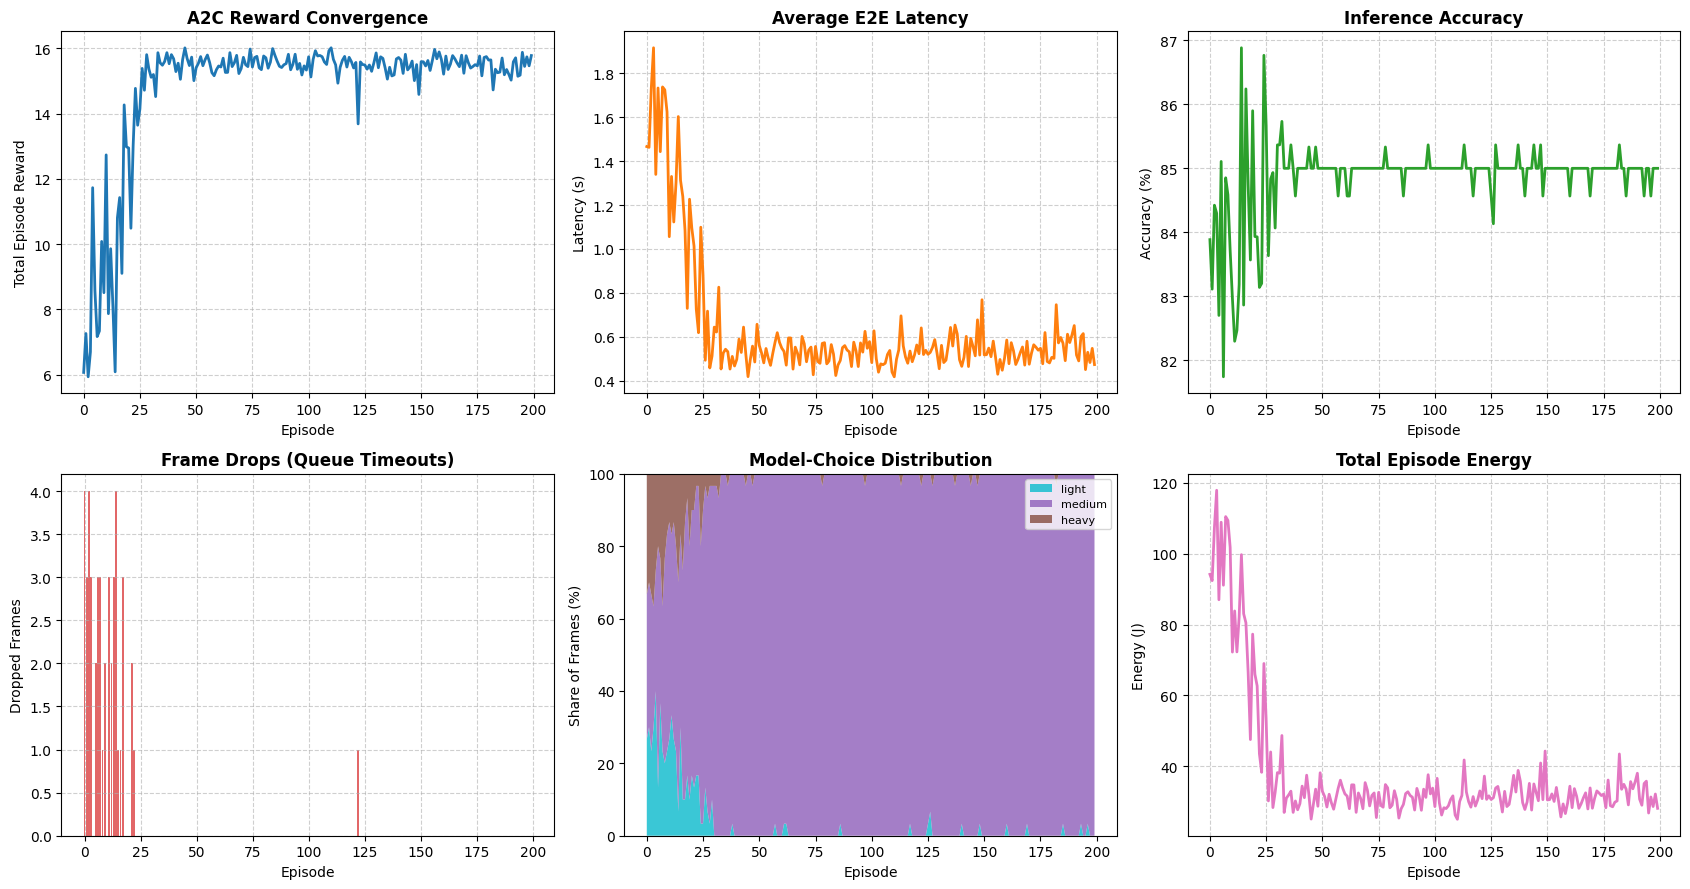


Final episode: accuracy 85.0%, latency 0.474s, energy 28.17J, drops 0
Model choice L/M/H: 0.0%/100.0%/0.0%


In [ ]:
def plot_history(hist, run_id=None, save=True):
    fig, axs = plt.subplots(2, 3, figsize=(17, 9))

    panels = [
        (axs[0, 0], hist['rewards'], 'tab:blue', "A2C Reward Convergence", "Total Episode Reward"),
        (axs[0, 1], hist['latencies'], 'tab:orange', "Average E2E Latency", "Latency (s)"),
        (axs[0, 2], [a * 100 for a in hist['accuracies']], 'tab:green',
         "Inference Accuracy", "Accuracy (%)"),
    ]
    for ax, data, color, title, ylabel in panels:
        ax.plot(data, color=color, linewidth=2)
        ax.set_title(title, fontsize=12, fontweight='bold')
        ax.set_xlabel("Episode"); ax.set_ylabel(ylabel)
        ax.grid(True, linestyle='--', alpha=0.6)

    axs[1, 0].bar(range(len(hist['drops'])), hist['drops'], color='tab:red', alpha=0.7)
    axs[1, 0].set_title("Frame Drops (Queue Timeouts)", fontsize=12, fontweight='bold')
    axs[1, 0].set_xlabel("Episode"); axs[1, 0].set_ylabel("Dropped Frames")
    axs[1, 0].grid(True, linestyle='--', alpha=0.6)

    eps = range(len(hist['complexity_fracs']))
    axs[1, 1].stackplot(
        eps,
        [f['light'] * 100 for f in hist['complexity_fracs']],
        [f['medium'] * 100 for f in hist['complexity_fracs']],
        [f['heavy'] * 100 for f in hist['complexity_fracs']],
        labels=['light', 'medium', 'heavy'],
        colors=['tab:cyan', 'tab:purple', 'tab:brown'], alpha=0.85)
    axs[1, 1].set_title("Model-Choice Distribution", fontsize=12, fontweight='bold')
    axs[1, 1].set_xlabel("Episode"); axs[1, 1].set_ylabel("Share of Frames (%)")
    axs[1, 1].set_ylim(0, 100); axs[1, 1].legend(loc='upper right', fontsize=8)

    axs[1, 2].plot(hist['energy'], color='tab:pink', linewidth=2)
    axs[1, 2].set_title("Total Episode Energy", fontsize=12, fontweight='bold')
    axs[1, 2].set_xlabel("Episode"); axs[1, 2].set_ylabel("Energy (J)")
    axs[1, 2].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    if save and run_id:
        os.makedirs("results", exist_ok=True)
        path = f"results/edge_vision_results_{run_id}.png"
        plt.savefig(path, dpi=150)
        print(f"Saved to {path}")
    plt.show()


plot_history(history, RUN_ID)

final = {k: history[k][-1] for k in ('rewards', 'latencies', 'energy', 'drops', 'accuracies')}
print(f"\nFinal episode: accuracy {final['accuracies']*100:.1f}%, "
      f"latency {final['latencies']:.3f}s, energy {final['energy']:.2f}J, "
      f"drops {final['drops']}")
print(f"Model choice L/M/H: " + "/".join(
    f"{history['complexity_fracs'][-1][k]*100:.1f}%" for k in ('light', 'medium', 'heavy')))

## 12. Baseline comparison

Is the learned policy actually better than a hardcoded configuration? These
three fixed policies run through the **same** simulator, cost model, and
frame sampling, so the comparison is like-for-like:

- **Random** — uniform over the 17 valid actions
- **Cheapest** — always `(light, cut 0)`: minimal local compute, maximal offload
- **Static Medium** — always `(medium, cut 3)`: the naive middle choice
- **Our RL** — the trained policy, evaluated greedily (`epsilon=0`)

In [ ]:
class RandomPolicy:
    name = "Random"
    def __init__(self, agent):   # reuse the same action mask, not all 21 actions
        self.valid = agent.valid_action_indices
        self.num_cutpoints = agent.num_cutpoints
    def act(self, state):
        idx = self.valid[torch.randint(len(self.valid), (1,))].item()
        return (idx // self.num_cutpoints, idx % self.num_cutpoints)


class CheapestPolicy:
    name = "Cheapest"
    def act(self, state):
        return (0, 0)


class StaticMediumPolicy:
    name = "Static Medium"
    def act(self, state):
        return (1, 3)


class TrainedRLPolicy:
    name = "Our RL"
    def __init__(self, agent):
        self.agent = agent
    def act(self, state):
        action, _ = self.agent.get_action(state, epsilon=0.0)
        return action


def evaluate_policy(policy, num_episodes=20, steps_per_episode=30,
                    seed=42, frame_sampling='random'):
    """Pure evaluation -- no learning updates. frame_sampling should match
    whatever the trained policy saw, or the two sides see different slices
    of the dataset."""
    set_seed(seed)
    sim = EdgeSystemSimulator()
    analyzer = ImageAnalyzer()
    ep_acc, ep_lat, ep_energy, ep_drops = [], [], [], []

    for ep in range(1, num_episodes + 1):
        sim.reset()
        bandwidth_trace = sim.generate_bandwidth_trace(steps_per_episode)
        accs, lats, energies, drops = [], [], [], 0

        for t in range(steps_per_episode):
            if USE_REAL_DATASET:
                idx = (random.randrange(len(FRAME_PATHS)) if frame_sampling == 'random'
                       else ((ep - 1) * steps_per_episode + t) % len(FRAME_PATHS))
                try:
                    frame = load_real_frame(FRAME_PATHS[idx])
                except Exception:
                    frame = generate_synthetic_frame('medium')
            else:
                frame = generate_synthetic_frame(random.choice(['low', 'medium', 'high']))

            norm_entropy, edge_density = analyzer.analyze(frame)
            complexity_type = ('low' if edge_density < 0.04
                               else 'medium' if edge_density < 0.12 else 'high')
            bandwidth = bandwidth_trace[t]
            state = [sim.local_queue_time, sim.offload_queue_time, bandwidth,
                     sim.local_queue_time + sim.offload_queue_time,
                     norm_entropy, edge_density, sim.remaining_battery]

            delay, energy, acc, dropped = sim.step(policy.act(state), t,
                                                   complexity_type, bandwidth)
            if dropped:
                drops += 1
                lats.append(sim.timeout_threshold); accs.append(0.0)
            else:
                lats.append(delay); accs.append(acc)
            energies.append(energy)

        ep_acc.append(safe_mean(accs)); ep_lat.append(np.mean(lats))
        ep_energy.append(np.sum(energies)); ep_drops.append(drops)

    return {'policy': policy.name,
            'accuracy': float(np.mean(ep_acc)) * 100,
            'latency': float(np.mean(ep_lat)),
            'energy': float(np.mean(ep_energy)),
            'drops': float(np.mean(ep_drops))}

In [ ]:
#@title Run baseline comparison { display-mode: "form" }
BASELINE_EPISODES = 20  #@param {type:"integer"}

policies = [
    RandomPolicy(trained_agent),
    CheapestPolicy(),
    StaticMediumPolicy(),
    TrainedRLPolicy(trained_agent),
]

results = [evaluate_policy(p, num_episodes=BASELINE_EPISODES,
                           steps_per_episode=STEPS_PER_EPISODE,
                           seed=SEED, frame_sampling=FRAME_SAMPLING)
           for p in policies]

try:
    import pandas as pd
    df = pd.DataFrame(results).rename(columns={
        'policy': 'Policy', 'accuracy': 'Accuracy (%)', 'latency': 'Latency (s)',
        'energy': 'Energy (J)', 'drops': 'Drops/ep'})
    display(df.round(3).style.hide(axis='index'))
except ImportError:
    for r in results:
        print(f"{r['policy']:<15} {r['accuracy']:5.1f}%  {r['latency']:.3f}s  "
              f"{r['energy']:6.2f}J  {r['drops']:.2f} drops/ep")

Policy,Accuracy (%),Latency (s),Energy (J),Drops/ep
Random,83.606000,1.518000,94.156000,3.650000
Cheapest,71.975000,0.155000,9.794000,0.000000
Static Medium,85.000000,1.335000,80.678000,6.050000
Our RL,85.000000,0.527000,31.046000,0.000000


## 13. Export

In [ ]:
#@title Download results { display-mode: "form" }
SAVE_CHART = True  #@param {type:"boolean"}
SAVE_AGENT = True  #@param {type:"boolean"}

from google.colab import files

if SAVE_CHART:
    chart = f"results/edge_vision_results_{RUN_ID}.png"
    if os.path.exists(chart):
        files.download(chart)
    else:
        print(f"{chart} not found -- re-run the plotting cell first.")

if SAVE_AGENT:
    weights = f"results/agent_{RUN_ID}.pt"
    os.makedirs("results", exist_ok=True)
    torch.save(trained_agent.network.state_dict(), weights)
    files.download(weights)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<a id="known_limitation"></a>
## Known limitation

A DAG-structured CNN with partition-point-aware forward passes exists in the
original `Edge.py` (`DAGVisionModel`), but it is **never invoked** — and it is
omitted from this notebook rather than included as dead code, since nothing
here calls it.

Delay, energy, and accuracy all come from the fixed per-complexity lookup
tables in `EdgeSystemSimulator` (§7), not from running a network on frames.
The frames themselves *are* real and *are* analyzed — entropy and edge density
genuinely come from the pixels — but the cost of a chosen action is modeled,
not measured.

That bounds what the baseline comparison in §12 shows: the trained policy
finds a better **cost-model** operating point than the fixed baselines. It
does not establish real-world accuracy. Wiring `DAGVisionModel` into
`EdgeSystemSimulator.step()` — running the actual forward passes and timing
them — is what would close that gap.